# KQC XMonsDirectCoupling — three directly coupled Swissmons with T-tapped readouts (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/xmons_direct_coupling.py` (class `XMonsDirectCoupling`, default
parameters; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/xmons_direct_coupling.py`). Three Swissmon ("Finnmon") qubits sit
in a row at the chip centre; neighbouring arm tips face each other across their 24 µm gaps and a 10 µm ground
strip, which is the direct qubit–qubit coupling. Each qubit's coupler 1 feeds an 86 Ω readout resonator
(a = 5, b = 20 µm) that runs straight up to a T: the T's side arm (the "tail") makes up the resonator length and
ends shorted, its top arm tapers to 10/6 µm and couples through a 4-finger capacitor into a probe-line T at
y = 7900 µm. The probe line (NW → NE) has an input finger capacitor (8 fingers, 55.4 µm, "35 fF"). Every qubit has
a charge line and a flux line from an SMA8 launcher; four junction-test arrays sit on the edges.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — it is
not a replica. We distribute the rebuild under GPL-3.0. The table says what is kept and what the PDK changes.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` (dicing edge, IQM markers, labels) | same 10 × 10 mm (the SMA8 launchers sit on its edges; it does not fit the 7.5 mm die), Quantcore die frame: L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "XMDC" |
| launchers | SMA8, all eight, `launcher_indent` 800 µm (outer etch 20 µm from the edge) | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in) |
| substrate | KQC simulation default silicon, εr 11.45 | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed L_J 16 nH, C_J 2 fF) | Quantcore Nb/AlOx/Nb trilayer SQUIDs, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH, C_J 15 fF; the four junction-test arrays get the same SQUID |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band is drawn |
| elements, positions, routes | — | kept: every KQC element with the source's parameters, positions and orientations; launcher waypoints derived from the launcher ports |
| placement | centred | centred (checked below, no shift) |

**Kept exactly:** the three `Swissmon`s with KQC's per-qubit parameters (coupler lengths 158/140/158 µm, coupler
gaps 90/102/90 µm, charge-line offsets) at x = 4650, 5000, 5350 µm; per readout the chain probe-line
`WaveguideCoplanarSplitter` → `FingerCapacitorSquare` (60.8 / 61.55 / 58.1 µm fingers) → `WaveguideCoplanarTaper`
(5/20 → 10/6 µm, 100 µm) → 86 Ω `WaveguideCoplanarSplitter`, snapped port to port as KQC aligns them; the
straight to the qubit; the tail with KQC's length formula (totals 4868.6 / 4682.3 / 4686.7 µm); the input
capacitor 300 µm left of QB1; the charge- and flux-line paths; the junction-test arrays.

**Simplified:** the `n_bridges` airbridges along the lines are left out.

**LOM approximations (stated):** the qubit–qubit coupling is a *declared* coupling (`d.couple`) with an
**assumed 0.3 fF** (no route or snap carries it; the C-matrix of the `qubits` sim group replaces it). The T-tapped
readout (straight + 86 Ω T + shorted tail) is one λ/4 `TLres` with the summed length.

The notebook walks through the build step by step: setup and the PDK → die and frame → launchers → components →
routes → DRC → netlist → LOM simulation → FEM jobs → results back → one design change → fab export →
snapshots → summary.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (the KQC grid has ≈ 0.8 M holes on 1/0 and 3/0) (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import junction_from_fingers

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")                            # design JSON + final snapshots
STEPS = Path("build/snapshots/xmonsdirectcoupling")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction from the PDK rule.** KQC draws a SQUID in every Swissmon. `trilayer_junction` turns it into the
Quantcore trilayer SQUID: two junctions whose straight finger is KQC's `junction_width` (the bent finger stays at
the PDK 0.6 µm). With the nominal L_J (6.73 nH, the 0.5 × 0.6 µm junction at R_n 45 kΩ) as the SQUID's parallel
total, each junction is 0.25 × 0.6 µm. `JJ_PARAMS` go on the cell, `JUNCTION` (L_J, C_J) is what the LOM and the
FEM junction ports use.

In [4]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


## 3 · The die and its frame

`Designer(...)` starts the chip: the 10 × 10 mm box, all eight SMA8 sample-holder launchers (KQC's default names
NW, NE, EN, ES, SE, SW, WS, WN) and the chip name "XMDC", which the Quantcore frame writes as the device ID on a
free edge. `with_grid=True` asks for KQC's whole-area ground grid (the original's cheese): the PDK band is then not
added (chip `cheese` stays `"auto"`).

The frame itself is the PDK default: L dicing markers on 1000/0 at the corners, 3 × 3 alignment grids on 1001/0
and the chip boundary on 100/0. KQC's own `ChipFrame` is not drawn.

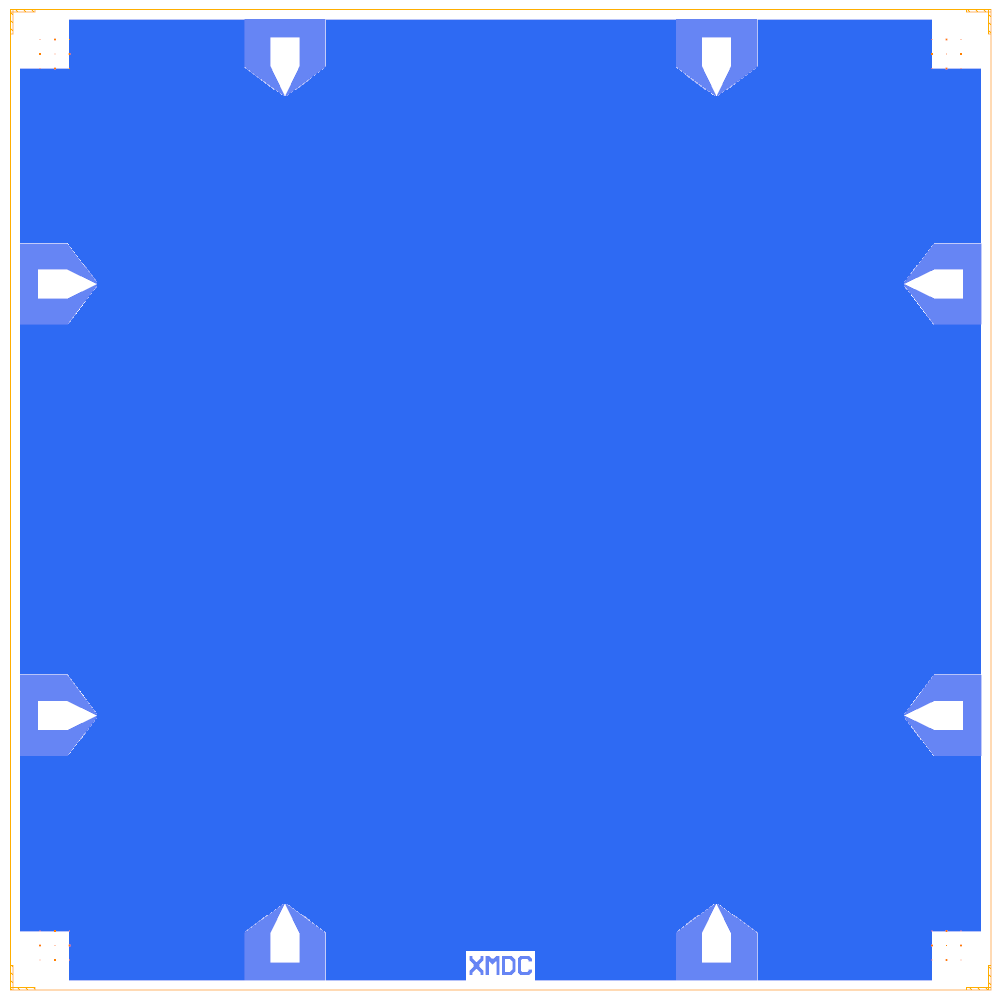

In [5]:
d = Designer("xmonsdirectcoupling", box=(0, 0, 10000, 10000), launchers="SMA8",
             chip={"name_chip": "XMDC", "with_grid": True}, live=LIVE)
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For KQC
sample-holder launchers the Designer applies it by computing `launcher_indent` (die edge → launcher port): RF
launcher = 100 µm + taper (300 µm) + pad (300 µm) + frame gap (180 µm) = **880 µm** (KQC: 800 µm, i.e. the outer
edge 20 µm from the edge). Every route below starts from these ports or from waypoints derived from them, so
nothing else moves with the rule. (Stand-alone pads, e.g. a `BondPad`, take `edge="auto"` in `d.add` instead; this
chip has none.)

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.NW | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.NE | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.EN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.ES | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.SE | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.SW | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.WS | launcher port | w | port 880 µm in (indent from the rule) | ✓ |
| chip.WN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

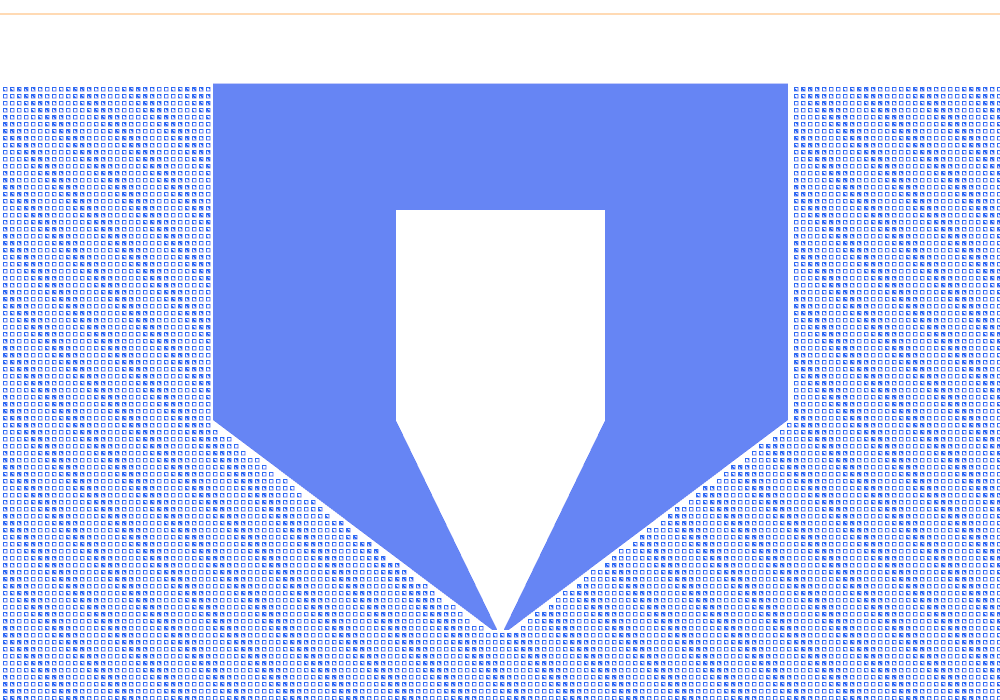

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.NW")
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## 5 · Components

**Junction-test arrays.** KQC's `JunctionTestPads` on the four edges (1300 × 2500 µm areas, horizontal
junctions), with the same trilayer SQUID.

**Qubits.** Three KQC `Swissmon`s on y = 5000 µm: 146 µm arms, 24 µm arm width and gap, port widths 10/5/10 µm,
only coupler 1 drawn (`cpl_length` [0, 158 | 140 | 158, 0]). The step between centres is 24 + 24 + 2 × 146 µm,
plus the 10 µm ground strip between facing arm tips. Ports: `cplr0`–`cplr2`, `drive`, `flux`. The SQUID carries
the trilayer junction parameters from step 2.

**The direct coupling.** Nothing in the layout joins the facing arm tips (they couple through the 24 + 10 + 24 µm
gap), so the LOM cannot see it from the netlist. `d.couple` declares it: an assumed 0.3 fF between neighbouring
islands, replaced by the `qubits` C-matrix once that job is solved.

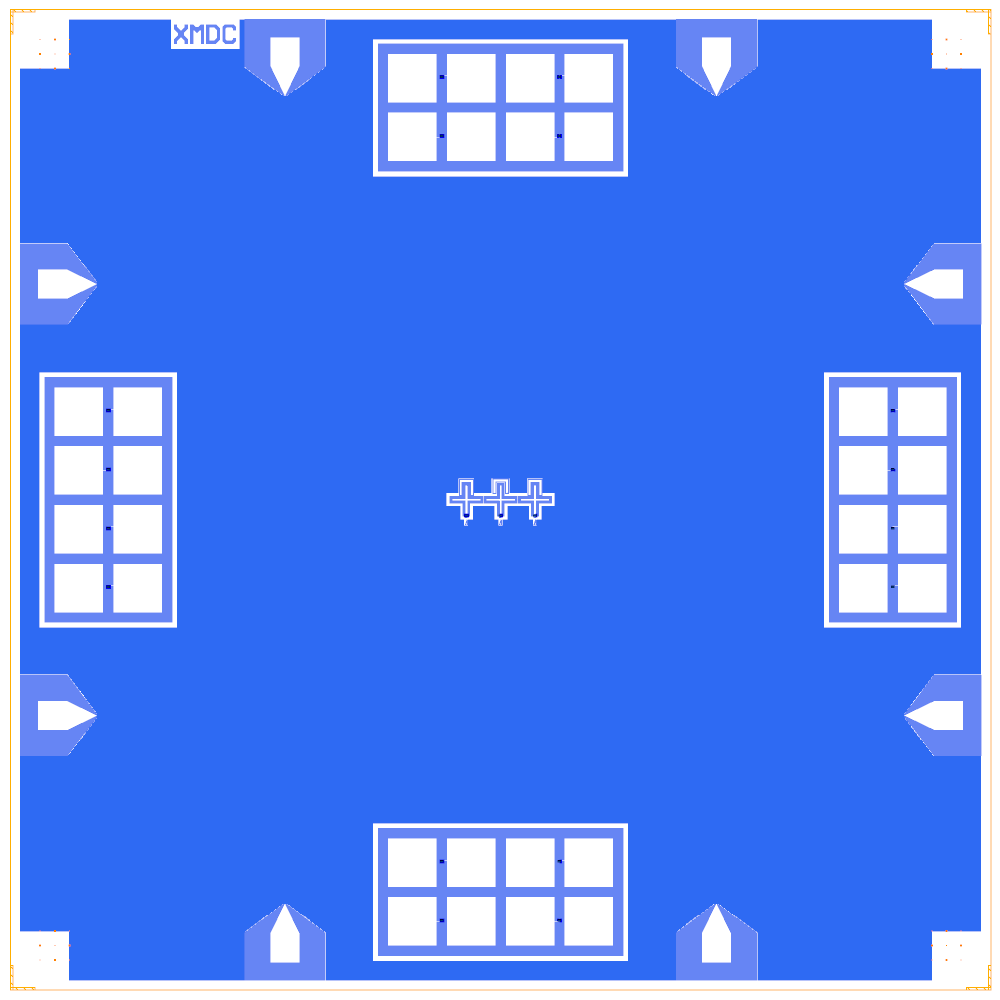

In [7]:
with d.batch():
    JTP = "kqcircuits.test_structures.junction_test_pads.junction_test_pads.JunctionTestPads"
    for name, at, (w, h) in (("JT_W", (350, 3750), (1300, 2500)), ("JT_S", (3750, 350), (2500, 1300)),
                             ("JT_E", (8350, 3750), (1300, 2500)), ("JT_N", (3750, 8350), (2500, 1300))):
        d.add(name, JTP, at=at, margin=50, area_width=w, area_height=h, junctions_horizontal=True, **JJ_PARAMS)

    # qubits: arm tips 24 + 10 + 24 µm apart (KQC qubit_step + qubit_spacing)
    common = dict(arm_length=[146] * 4, island_r=2, port_width=[10, 5, 10], arm_width=[24] * 4, gap_width=[24] * 4)
    step = 24 + 24 + 2 * 146
    qubits = {
        "QB1": (5000 - step - 10, dict(cpl_gap=[110, 90, 110], cpl_length=[0, 158, 0], cl_offset=[150, -150])),
        "QB2": (5000, dict(cpl_gap=[110, 102, 110], cpl_length=[0, 140, 0], cl_offset=[150, 150])),
        "QB3": (5000 + step + 10, dict(cpl_gap=[110, 90, 110], cpl_length=[0, 158, 0], cl_offset=[-150, -150])),
    }
    for n, (x, own) in qubits.items():
        d.add(n, "Swissmon", at=(x, 5000), cpl_width=[60, 24, 60], junction=JUNCTION, **JJ_PARAMS, **common, **own)
    d.couple("C12", "QB1", "QB2", C_fF=0.3, note="arm tips facing across 24 + 10 + 24 µm (assumed value)")
    d.couple("C23", "QB2", "QB3", C_fF=0.3, note="arm tips facing across 24 + 10 + 24 µm (assumed value)")
snap(d, STEPS / "3_components.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 6 · Routes

**Readout chains.** Per qubit, from the probe line down: a probe-line T (`WaveguideCoplanarSplitter`, arms
11/11/31 µm) at the qubit's x and y = 7900 µm; the 4-finger `FingerCapacitorSquare` snapped to its bottom arm; a
`WaveguideCoplanarTaper` 10/6 → 5/20 µm (100 µm long); the 86 Ω T (arms 22.5/22.5/62.5 µm, a = 5, b = 20 µm).
`snap=` places each by one port onto the previous one's port, as KQC aligns them. The straight `RS` runs from the
86 Ω T to the qubit's coupler 1 (a = 5, b = 20 µm); the tail `RR` leaves the T's third arm, turns down and ends
shorted (`d.free_end(..., term=0)`). KQC's formula gives the tail length from the total: total − straight − T arm
− the 90° bend + one radius.

In [8]:
def corner(ref, dist=100.0):                     # KQC "<port>_corner": one turn radius out along the port
    x, y, a = port_info(d, ref)
    return (x + dist * math.cos(math.radians(a)), y + dist * math.sin(math.radians(a)))


TOTAL = {1: 2421.5 + 2447.1, 2: 2436 + 2246.3, 3: 2438.5 + 2248.2}   # KQC readout totals (µm)
FINGERS = {1: 60.8, 2: 61.55, 3: 58.1}                              # finger-capacitor finger lengths (µm)
with d.batch():
    for i in (1, 2, 3):
        qx, qy = port_xy(d, f"QB{i}.cplr1")
        tee = d.add(f"PL{i}", "WaveguideCoplanarSplitter", at=(qx, 7900), lengths=[11, 11, 31],
                    port_names=["right", "left", "bottom"])
        cap = d.add(f"RC{i}", "FingerCapacitorSquare", snap="b", to=tee.bottom, finger_number=4,
                    finger_length=FINGERS[i], finger_gap_end=5, finger_gap=5, finger_width=15, ground_padding=10)
        tap = d.add(f"TP{i}", "WaveguideCoplanarTaper", snap="b", to=cap.a, a=5, b=20, a2=10, b2=6, taper_length=100)
        rx = d.add(f"RX{i}", "WaveguideCoplanarSplitter", snap="right", to=tap.a, lengths=[22.5, 22.5, 62.5],
                   a_list=[5, 5, 5], b_list=[20, 20, 20], port_names=["right", "left", "bottom"])
        d.route(f"RS{i}", rx.left, f"QB{i}.cplr1", a=5, b=20)
        (lx, ly), (rgx, rgy) = port_xy(d, f"RX{i}.left"), port_xy(d, f"RX{i}.right")
        non_tail = math.hypot((lx + rgx) / 2 - qx, (ly + rgy) / 2 - qy)
        tail = TOTAL[i] - non_tail - 62.5 - math.pi / 2 * 100 + 100
        cx, cy = corner(f"RX{i}.bottom")
        d.route(f"RR{i}", rx.bottom, d.free_end((cx, cy - tail), dir=90, term=0), a=5, b=20, r=100)

**Probe line.** NW → the input finger capacitor (8 fingers, 55.4 µm; 300 µm left of QB1's T) → the three T's →
NE, at y = 7900 µm; the legs from NW and NE turn at the launcher's x. **Charge lines** (6 µm open end at the drive
port) and **flux lines** follow KQC's paths; their waypoints come from the launcher ports.

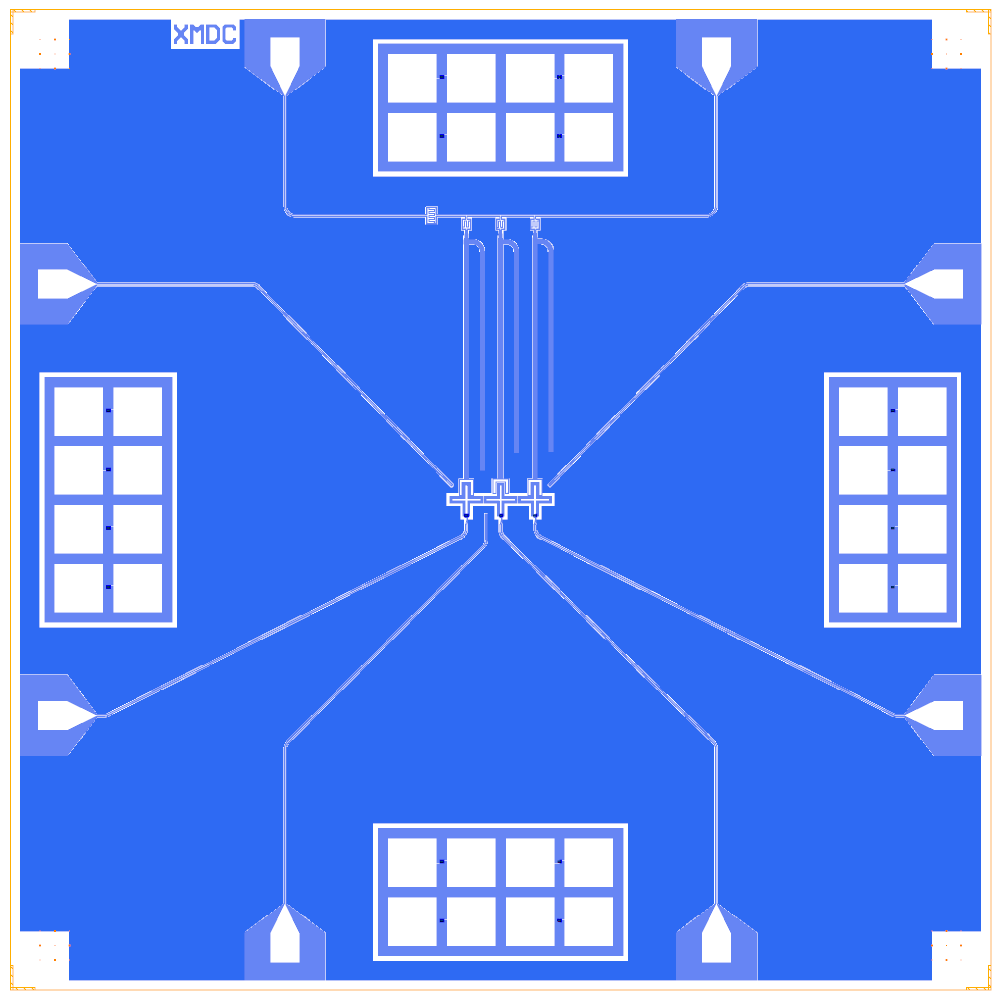

{'readout 1': 4868.6, 'readout 2': 4682.3, 'readout 3': 4686.7} (straight + T + tail; KQC totals 4868.6 / 4682.3 / 4686.7)


In [9]:
with d.batch():
    nwx, _ = port_xy(d, "chip.NW")
    nex, _ = port_xy(d, "chip.NE")
    q1x, _ = port_xy(d, "QB1.cplr1")
    pin = add_aligned(d, "IN", "FingerCapacitorSquare", "b", (q1x - 300, 7900), finger_number=8, finger_length=55.4,
                      finger_gap_end=5, finger_gap=5, finger_width=15, ground_padding=10)
    d.route("P0", "chip.NW", pin.a, nodes=[(nwx, 7900)])
    d.route("P1", pin.b, "PL1.left")
    d.route("P2", "PL1.right", "PL2.left")
    d.route("P3", "PL2.right", "PL3.left")
    d.route("P4", "PL3.right", "chip.NE", nodes=[(nex, 7900)])

    _, wny = port_xy(d, "chip.WN")
    _, wsy = port_xy(d, "chip.WS")
    swx, _ = port_xy(d, "chip.SW")
    sex, _ = port_xy(d, "chip.SE")
    _, esy = port_xy(d, "chip.ES")
    _, eny = port_xy(d, "chip.EN")
    d2x, d2y = port_xy(d, "QB2.drive")
    d.route("DL1", "chip.WN", "QB1.drive", nodes=[(nwx - 300, wny)], term2=6)
    d.route("FL1", "chip.WS", "QB1.flux", nodes=[corner("chip.WS"), corner("QB1.flux")])
    d.route("DL2", "chip.SW", "QB2.drive", nodes=[(swx, wsy - 300), (d2x, d2y - 300)], term2=6)
    d.route("FL2", "chip.SE", "QB2.flux", nodes=[(sex, esy - 300), corner("QB2.flux")])
    d.route("DL3", "chip.EN", "QB3.drive", nodes=[(nex + 300, eny)], term2=6)
    d.route("FL3", "chip.ES", "QB3.flux", nodes=[corner("chip.ES"), corner("QB3.flux")])
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
lengths = d.result.route_lengths()
print({f"readout {i}": round(lengths[f"RS{i}"] + 62.5 + 45 / 2 + lengths[f"RR{i}"], 1) for i in (1, 2, 3)},
      "(straight + T + tail; KQC totals 4868.6 / 4682.3 / 4686.7)")

**Sim groups and centring.** A sim group names a FEM sub-problem: the three qubits together (Q3D C-matrix: it
gives the real direct couplings) and each qubit with its readout chain. `center_in_die` checks that the content
sits centred in the die (PDK placement rule) and shifts it if it is more than 50 µm off — here it is centred, so
nothing moves. Then the design is saved: `xmonsdirectcoupling.json` is what DRC, LOM, FEM and `qcc` read.

In [10]:
d.sim_group("qubits", ["QB1", "QB2", "QB3"], analyses=["q3d_cmatrix"])
for i in (1, 2, 3):
    d.sim_group(f"QB{i}_RR{i}", [f"QB{i}", f"RS{i}", f"RX{i}", f"RR{i}"], analyses=["q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "xmonsdirectcoupling.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


<Designer xmonsdirectcoupling: 20 instances, 17 routes, live=False> → examples\designs\kqc\xmonsdirectcoupling.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** DRC clean, with 6 `dangling_port` warnings: each Swissmon's zero-length couplers 0 and 2 (`cpl_length` [0, …, 0]; the LOM puts their ports on ground). No PDK design warning: the SQUIDs' device R_n is 45 kΩ (the parallel R_n of two 90 kΩ junctions) and f_q (≈ 6.5 GHz) is inside the 4–8 GHz band. `pdk_report` gives KQC's grid as the cheese ("the original design's own"), the content centred (0, 0) and "Quantcore Squid × 3" (the qubits; the junction-test arrays draw the same SQUID but are not counted).

In [11]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 6 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 6 | QB1.cplr0 is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 3 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit nodes,
routes join nodes (or become transmission-line resonators), launchers are 50 Ω ports or drive / flux controls.

Swissmon → an island node (C and the SQUID to ground) and a coupler-1 node (C_g to the island, C to ground). The
declared couplings C12 and C23 join neighbouring islands. The readout straight, the 86 Ω T and the tail form one
λ/4 `TLres` (shorted at the tail's end); the taper and the finger capacitor couple it to the probe line, which runs
between the NW and NE 50 Ω ports through the input capacitor. Charge and flux lines are drive / flux controls on
the SQUIDs.

In [12]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB1's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("QB1."))))

**12 nodes · 37 branches · 6 controls · 6 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `QB1` | `QB1.island` |
| `QB1.cplr1` | `QB1.cplr1`, `RC1.a`, `TP1.line`, `RX1.t` |
| `QB2` | `QB2.island` |
| `QB2.cplr1` | `QB2.cplr1`, `RC2.a`, `TP2.line`, `RX2.t` |
| `QB3` | `QB3.island` |
| `QB3.cplr1` | `QB3.cplr1`, `RC3.a`, `TP3.line`, `RX3.t` |
| `PL1.t` | `PL1.t`, `RC1.b`, `PL2.t`, `RC2.b`, `PL3.t`, `RC3.b`, `IN.b`, `chip.NE` |
| `IN.a` | `IN.a`, `chip.NW` |
| `chip.WN` | `chip.WN` |
| `chip.SW` | `chip.SW` |
| `chip.EN` | `chip.EN` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_QB1` | C | `QB1` – `gnd` | 62.4 fF |
| `J_QB1` | SQUID | `QB1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB1_cplr1` | C | `QB1` – `QB1.cplr1` | 5 fF |
| `Cc_QB1_cplr1` | C | `QB1.cplr1` – `gnd` | 81.4 fF |
| `C_QB2` | C | `QB2` – `gnd` | 62.4 fF |
| `J_QB2` | SQUID | `QB2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB2_cplr1` | C | `QB2` – `QB2.cplr1` | 4.4 fF |
| `Cc_QB2_cplr1` | C | `QB2.cplr1` – `gnd` | 76.9 fF |
| `C_QB3` | C | `QB3` – `gnd` | 62.4 fF |
| `J_QB3` | SQUID | `QB3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB3_cplr1` | C | `QB3` – `QB3.cplr1` | 5 fF |
| `Cc_QB3_cplr1` | C | `QB3.cplr1` – `gnd` | 81.4 fF |
| `C_RC1` | C | `QB1.cplr1` – `PL1.t` | 20.1 fF |
| `C_RC1_a` | C | `QB1.cplr1` – `gnd` | 13 fF |
| `C_RC1_b` | C | `PL1.t` – `gnd` | 13 fF |
| `C_RC2` | C | `QB2.cplr1` – `PL1.t` | 20.2 fF |
| `C_RC2_a` | C | `QB2.cplr1` – `gnd` | 13 fF |
| `C_RC2_b` | C | `PL1.t` – `gnd` | 13 fF |
| `C_RC3` | C | `QB3.cplr1` – `PL1.t` | 19.4 fF |
| `C_RC3_a` | C | `QB3.cplr1` – `gnd` | 13 fF |
| `C_RC3_b` | C | `PL1.t` – `gnd` | 13 fF |
| `C_IN` | C | `IN.a` – `PL1.t` | 39.8 fF |
| `C_IN_a` | C | `IN.a` – `gnd` | 21 fF |
| `C_IN_b` | C | `PL1.t` – `gnd` | 21 fF |
| `Port_NW` | R | `IN.a` – `gnd` | 50 Ω |
| `Port_NE` | R | `PL1.t` – `gnd` | 50 Ω |
| `Port_WN` | R | `chip.WN` – `gnd` | 50 Ω |
| `Port_SW` | R | `chip.SW` – `gnd` | 50 Ω |
| `Port_EN` | R | `chip.EN` – `gnd` | 50 Ω |
| `C_C12` | C | `QB1` – `QB2` | 0.3 fF |
| `C_C23` | C | `QB2` – `QB3` | 0.3 fF |
| `Cd_QB1` | C | `QB1` – `chip.WN` | 0.1 fF |
| `Cd_QB2` | C | `QB2` – `chip.SW` | 0.1 fF |
| `Cd_QB3` | C | `QB3` – `chip.EN` | 0.1 fF |
| `RR1` | TLres | `QB1.cplr1` – `gnd` | lambda/4, 4784 µm, 6.545 GHz |
| `RR2` | TLres | `QB2.cplr1` – `gnd` | lambda/4, 4597 µm, 6.810 GHz |
| `RR3` | TLres | `QB3.cplr1` – `gnd` | lambda/4, 4602 µm, 6.804 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `DL1` | drive | `J_QB1` | `DL1` | 4479 |
| `FL1` | flux_bias | `J_QB1` | `FL1` | 4295 |
| `DL2` | drive | `J_QB2` | `DL2` | 4811 |
| `FL2` | flux_bias | `J_QB2` | `FL2` | 4785 |
| `DL3` | drive | `J_QB3` | `DL3` | 4479 |
| `FL3` | flux_bias | `J_QB3` | `FL3` | 4295 |

**Unconnected ports:** `QB1.cplr0`, `QB1.cplr2`, `QB2.cplr0`, `QB2.cplr2`, `QB3.cplr0`, `QB3.cplr2`

**Builder notes:**

- QB1.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB1.cplr2: cpl_length 0 (no coupler), its port ends on ground
- QB2.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB2.cplr2: cpl_length 0 (no coupler), its port ends on ground
- QB3.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB3.cplr2: cpl_length 0 (no coupler), its port ends on ground
- RR1: one lambda/4 line of 4784 µm = route + ['RS1'] (the wires join it to its coupler end; any other branch on that conductor is a tap, not modelled as a separate line)
- RR2: one lambda/4 line of 4597 µm = route + ['RS2'] (the wires join it to its coupler end; any other branch on that conductor is a tap, not modelled as a separate line)
- RR3: one lambda/4 line of 4602 µm = route + ['RS3'] (the wires join it to its coupler end; any other branch on that conductor is a tap, not modelled as a separate line)
- Port_WS: both ends on gnd after merging conductors (dropped)
- Port_SE: both ends on gnd after merging conductors (dropped)
- Port_ES: both ends on gnd after merging conductors (dropped)

**QB1's ports → circuit nodes:**

| port | node |
|---|---|
| `QB1.cplr0` | `gnd` |
| `QB1.cplr1` | `QB1.cplr1` |
| `QB1.cplr2` | `gnd` |
| `QB1.drive` | `control:drive` |
| `QB1.flux` | `control:flux` |

## 9 · LOM simulation

QuCat finds the normal modes of the circuit (frequencies, κ into the 50 Ω ports, anharmonicities) and QuTiP
diagonalises the dressed Hamiltonian of the first modes (f_q, α, f_r, χ). First the three qubits with their declared
couplings; then each qubit with its readout chain and the whole probe line.

The three qubits are identical in the LOM (the same SQUID and nearly the same capacitances), so with the 0.3 fF
couplings their modes hybridise: each mode spreads over two or three junctions, and a per-pair static ZZ is not
defined (the ZZ table says so). Step 12 detunes one qubit to show the difference.

In [13]:
qubits_only = simulate_groups(d, {"QB1–QB2–QB3": ["QB1", "QB2", "QB3"]}, max_modes=3, excitations=[4, 4, 4])
display(Markdown("**Coupled qubits, QuCat normal modes:**\n\n" + modes_md(qubits_only["QB1–QB2–QB3"])))
display(Markdown("**Static ZZ (QuTiP; QB1–QB2 and QB2–QB3 are neighbours through C12, C23):**\n\n"
                 + zz_md(qubits_only)))

**Coupled qubits, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB1 | qubit | 6.7428 | 0 | 78.3 | J_QB2 0.36, J_QB1 0.32, J_QB3 0.32 |
| QB3 | qubit | 6.7558 | 0 | 117.5 | J_QB1 0.50, J_QB3 0.50 |
| QB2 | qubit | 6.7792 | 0 | 112.4 | J_QB2 0.64, J_QB1 0.18, J_QB3 0.18 |

**Static ZZ (QuTiP; QB1–QB2 and QB2–QB3 are neighbours through C12, C23):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| QB1–QB2–QB3 | QB1-QB3 | – | no | yes |
| QB1–QB2–QB3 | QB1-QB2 | – | yes | yes |
| QB1–QB2–QB3 | QB2-QB3 | – | yes | yes |

In [14]:
probe = ["IN", "PL1", "PL2", "PL3", "P0", "P1", "P2", "P3", "P4"]
groups = {f"QB{i}+RR{i}": [f"QB{i}", f"RS{i}", f"RX{i}", f"TP{i}", f"RC{i}", f"RR{i}"] + probe for i in (1, 2, 3)}
results = simulate_groups(d, groups)
display(Markdown(groups_md(results)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| QB1+RR1 | QB1 | 6.5205 | -255 | RR1 | 5.2042 | 10.2 | -2.3 |
| QB2+RR2 | QB2 | 6.5429 | -256.3 | RR2 | 5.4182 | 11.6 | -2.93 |
| QB3+RR3 | QB3 | 6.5218 | -253.8 | RR3 | 5.376 | 10.4 | -3.46 |

**Reading the numbers.** With the PDK SQUIDs the three coupled qubits sit at 6.74–6.78 GHz (KQC's assumed 16 nH gave ≈ 4.5 GHz). Each mode is spread over two or three junctions (participations 0.32–0.64), so the ZZ table reports every pair as hybridised. With their readout chains and the probe line: f_q 6.52 / 6.54 / 6.52 GHz, α ≈ −255 MHz; the λ/4 readouts at 5.20 / 5.42 / 5.38 GHz (below the qubits), κ 10.2 / 11.6 / 10.4 MHz, χ −2.3 / −2.9 / −3.5 MHz. The LOM merges straight + T + tail into one λ/4 of 4784 / 4597 / 4602 µm (the builder notes in step 8).

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one Q3D C-matrix job for the three qubits (its C-matrix replaces the assumed 0.3 fF couplings) and
one per qubit with its readout chain.

In [15]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

4 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| qubits · q3d_cmatrix | `build/jobs/xmonsdirectcoupling_qubits_q3d_cmatrix` | 1 · junction · `QB1.junction`<br>2 · junction · `QB2.junction`<br>3 · junction · `QB3.junction`<br>4 · edge · `DL1`<br>5 · edge · `DL2`<br>6 · edge · `DL3`<br>7 · edge · `FL1`<br>8 · edge · `FL2`<br>9 · edge · `FL3`<br>10 · edge · `RS1`<br>11 · edge · `RS2`<br>12 · edge · `RS3` | `QB1.island`, `QB2.island`, `QB3.island`, `DL1`, `DL2`, `DL3`, `RS1`, `RS2`, `RS3` |
| QB1_RR1 · q3d_cmatrix | `build/jobs/xmonsdirectcoupling_QB1_RR1_q3d_cmatrix` | 1 · junction · `QB1.junction`<br>2 · waveguide · `RX1.left`<br>3 · waveguide · `QB1.cplr1`<br>4 · waveguide · `RX1.bottom`<br>5 · edge · `DL1`<br>6 · edge · `DL2`<br>7 · edge · `FL1`<br>8 · edge · `FL2`<br>9 · edge · `P0`<br>10 · edge · `P3` | `QB1.island`, `RX1.left`, `QB1.cplr1`, `DL1`, `DL2`, `P0`, `P3` |
| QB2_RR2 · q3d_cmatrix | `build/jobs/xmonsdirectcoupling_QB2_RR2_q3d_cmatrix` | 1 · junction · `QB2.junction`<br>2 · waveguide · `RX2.left`<br>3 · waveguide · `QB2.cplr1`<br>4 · waveguide · `RX2.bottom`<br>5 · edge · `DL2`<br>6 · edge · `FL1`<br>7 · edge · `FL2`<br>8 · edge · `FL3`<br>9 · edge · `P1`<br>10 · edge · `P4` | `QB2.island`, `RX2.left`, `QB2.cplr1`, `DL2`, `P1` |
| QB3_RR3 · q3d_cmatrix | `build/jobs/xmonsdirectcoupling_QB3_RR3_q3d_cmatrix` | 1 · junction · `QB3.junction`<br>2 · waveguide · `RX3.left`<br>3 · waveguide · `QB3.cplr1`<br>4 · waveguide · `RX3.bottom`<br>5 · edge · `DL3`<br>6 · edge · `FL2`<br>7 · edge · `FL3`<br>8 · edge · `P2`<br>9 · edge · `P4` | `QB3.island`, `RX3.left`, `QB3.cplr1`, `DL3`, `P2` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [16]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for qubits · q3d_cmatrix, QB1_RR1 · q3d_cmatrix, QB2_RR2 · q3d_cmatrix, QB3_RR3 · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

A design change is a parameter change in the design, followed by a rebuild and a new LOM run. Here: give QB2 a
0.27 µm straight junction finger instead of 0.25 µm (L_J 6.73 → 6.24 nH, R_n 45.0 → 41.7 kΩ, still in the
window). QB2 moves up in frequency, away from QB1 and QB3; the table shows which modes this separates. The change
is made on a copy (`design_copy`), so `xmonsdirectcoupling.json` keeps the
nominal SQUID.

In [17]:
d2 = design_copy(DESIGN)
j = junction_from_fingers(0.27, 0.6, n=2)
d2["QB2"].set(junction_width=0.27, junction={"Lj_nH": round(j.lj_nH, 4), "Cj_fF": round(j.cj_fF, 3)})
after = simulate_groups(d2, {"QB1–QB2–QB3": ["QB1", "QB2", "QB3"]}, max_modes=3, excitations=[4, 4, 4])


def mode_rows(r):                                # QuCat modes: f and the junction participations (> 5 %)
    return {m.label: (m.f_GHz, ", ".join(f"{k} {v:.2f}" for k, v in m.participation.items() if v > 0.05))
            for m in r.modes if m.kind == "qubit"}


b, a = mode_rows(qubits_only["QB1–QB2–QB3"]), mode_rows(after["QB1–QB2–QB3"])
display(Markdown("**QB2 straight finger 0.25 → 0.27 µm**\n\n"
                 "| mode | before: f (GHz) · participation | after: f (GHz) · participation |\n|---|---|---|\n"
                 + "\n".join(f"| {k} | {b[k][0]:.4f} · {b[k][1]} | {a[k][0]:.4f} · {a[k][1]} |"
                             for k in sorted(set(a) & set(b)))))
display(Markdown("**Static ZZ after:**\n\n" + zz_md(after)))

**QB2 straight finger 0.25 → 0.27 µm**

| mode | before: f (GHz) · participation | after: f (GHz) · participation |
|---|---|---|
| QB1 | 6.7428 · J_QB1 0.32, J_QB2 0.36, J_QB3 0.32 | 6.7545 · J_QB1 0.50, J_QB3 0.50 |
| QB2 | 6.7792 · J_QB1 0.18, J_QB2 0.64, J_QB3 0.18 | 6.9821 · J_QB2 0.99 |
| QB3 | 6.7558 · J_QB1 0.50, J_QB3 0.50 | 6.7558 · J_QB1 0.50, J_QB3 0.50 |

**Static ZZ after:**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| QB1–QB2–QB3 | QB1-QB3 | – | no | yes |
| QB1–QB2–QB3 | QB1-QB2 | – | yes | yes |
| QB1–QB2–QB3 | QB2-QB3 | – | yes | yes |

**Result.** QB2 moves from 6.779 to 6.982 GHz (+203 MHz) and now lives on its own junction (participation 0.99). QB1 and QB3 stay hybridised with each other (0.50 / 0.50, at 6.755 / 6.756 GHz): they are mirror images, coupled through QB2, so detuning QB2 alone does not separate them, and the ZZ table still reports every pair as hybridised. A per-pair ZZ needs all three detuned (a second change, e.g. QB3 at 0.24 µm) or the C-matrix of the `qubits` group.

## 13 · Build and export

**The design file.** `xmonsdirectcoupling.json` (saved in step 6) is the whole design: `qcc build
examples/designs/kqc/xmonsdirectcoupling.json` rebuilds `build/xmonsdirectcoupling.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK
band is added. In this run: 735 491 polygons on 1/0 and 713 520 on 3/0 (the keep-outs merge with the neighbouring grid holes), 735 473 grid holes; the export takes ≈ 20 s here. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/xmonsdirectcoupling.json` writes the complete file.

In [18]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 735491 |
| 2/0 | JJ_STRAIGHT | 19 |
| 3/0 | M3 | 713520 |
| 4/0 | JJ_BENT | 19 |
| 50/0 | HSQ | 76 |
| 51/0 | SPACER_1 | 76 |
| 52/0 | SPACER_2 | 76 |
| 53/0 | SPACER_3 | 76 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 735473 holes on the mask.

→ `build/xmonsdirectcoupling_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out. This chip has no airbridges, so both settings give the same geometry.

In [19]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB1_RR1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

The full chip (KQC's grid fills the ground: at this scale its holes render as one tone); the three qubits with
their readout T's; QB2's trilayer SQUID; the QB1 readout capacitor on its probe-line T; the die frame's south-west
corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); QB2 in the **fab view** (the mask written in step 13:
base etch 1/0 with KQC's 5 µm grid holes cleared around the qubit, 3/0 with the keep-outs and the same holes, the
trilayer layers); and — for comparison — KQC's own `XMonsDirectCoupling` built stand-alone (KQC's ChipFrame,
Manhattan SQUIDs, no grid). The chip boundary 100/0 is drawn as an outline.

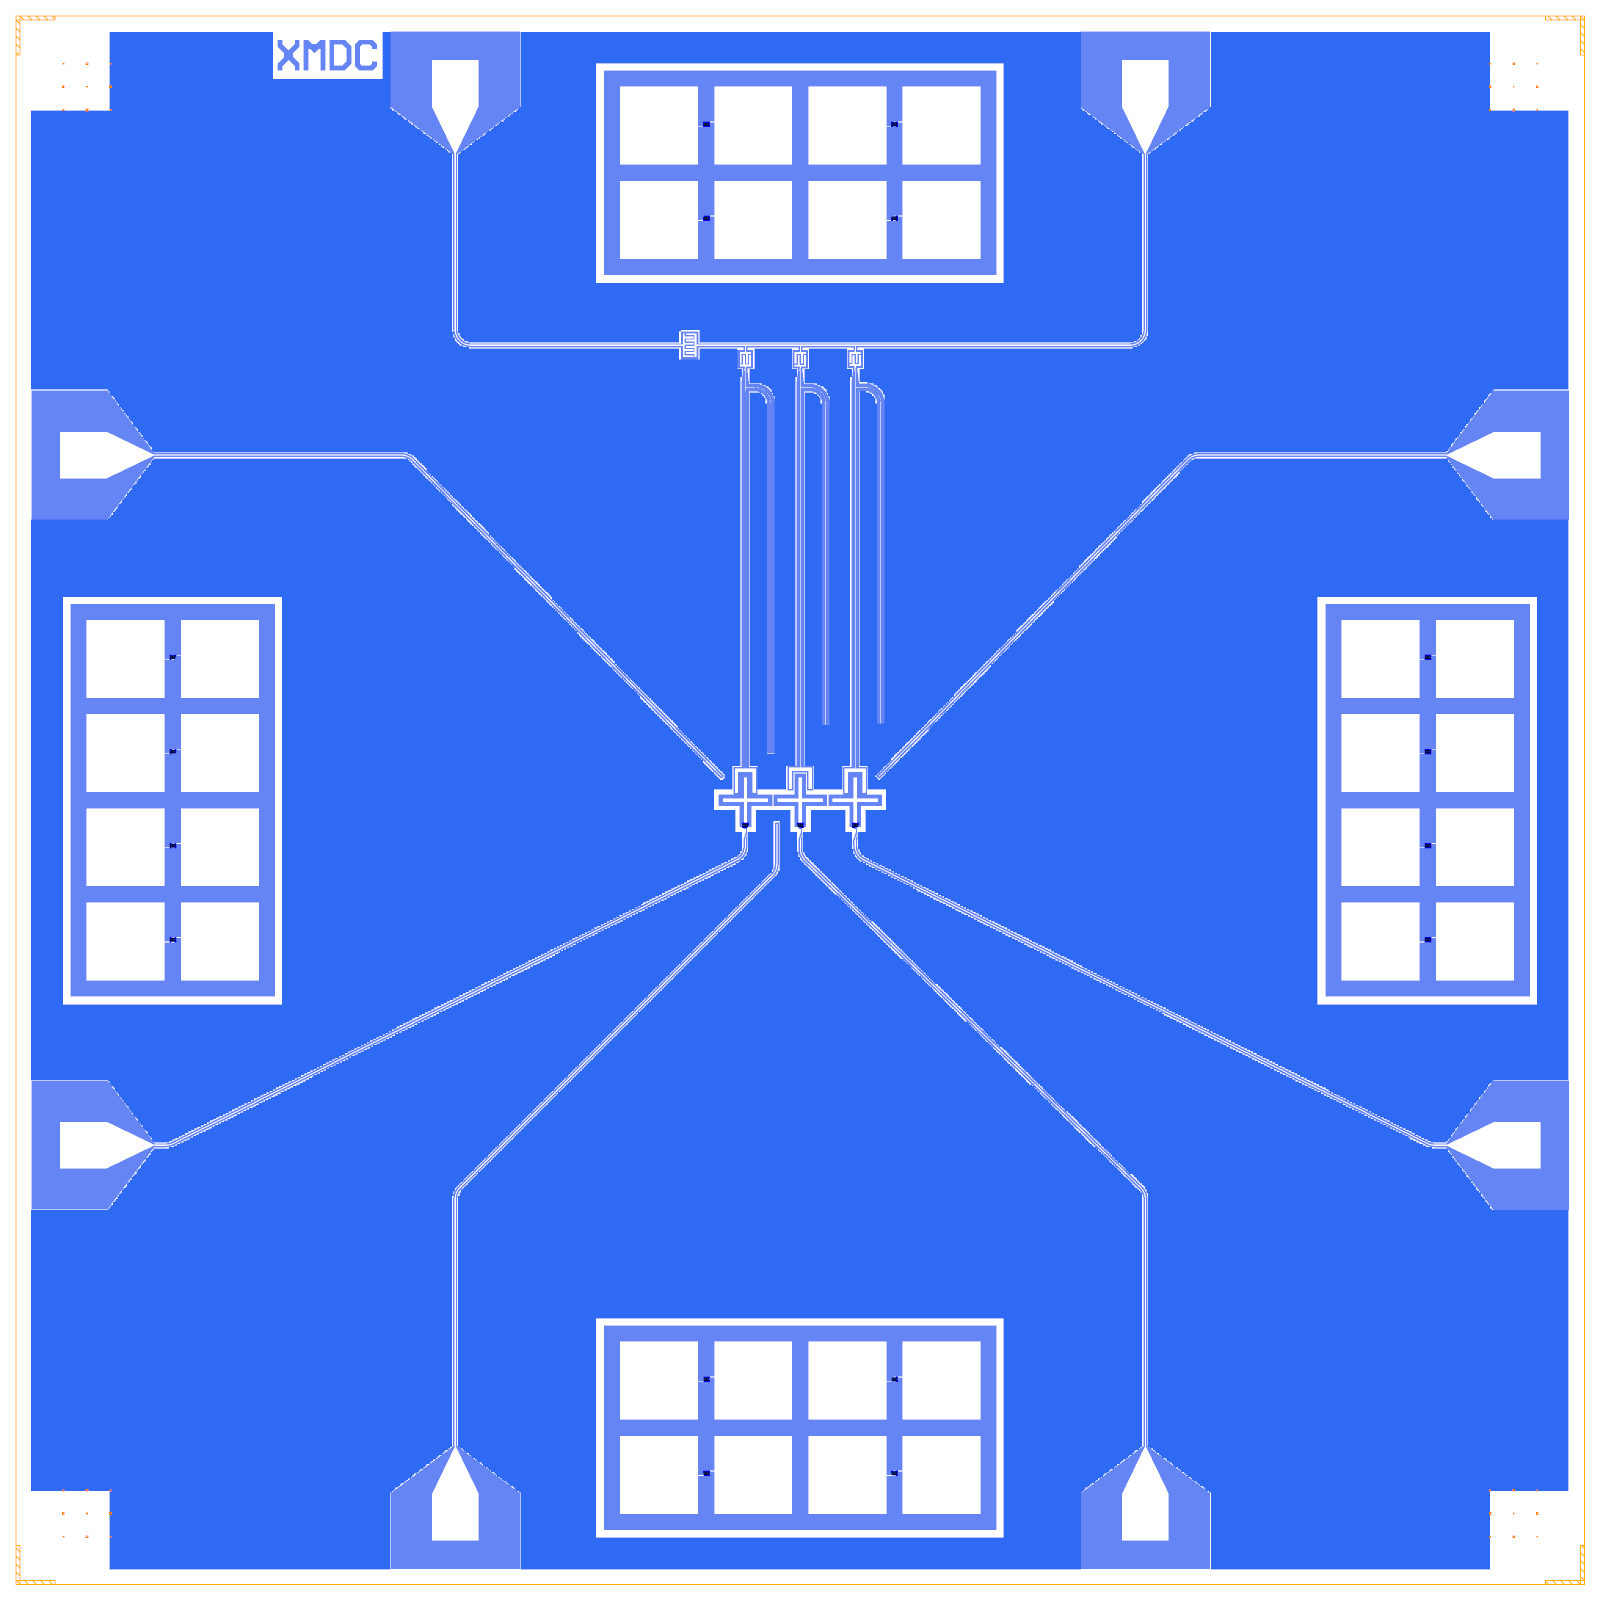

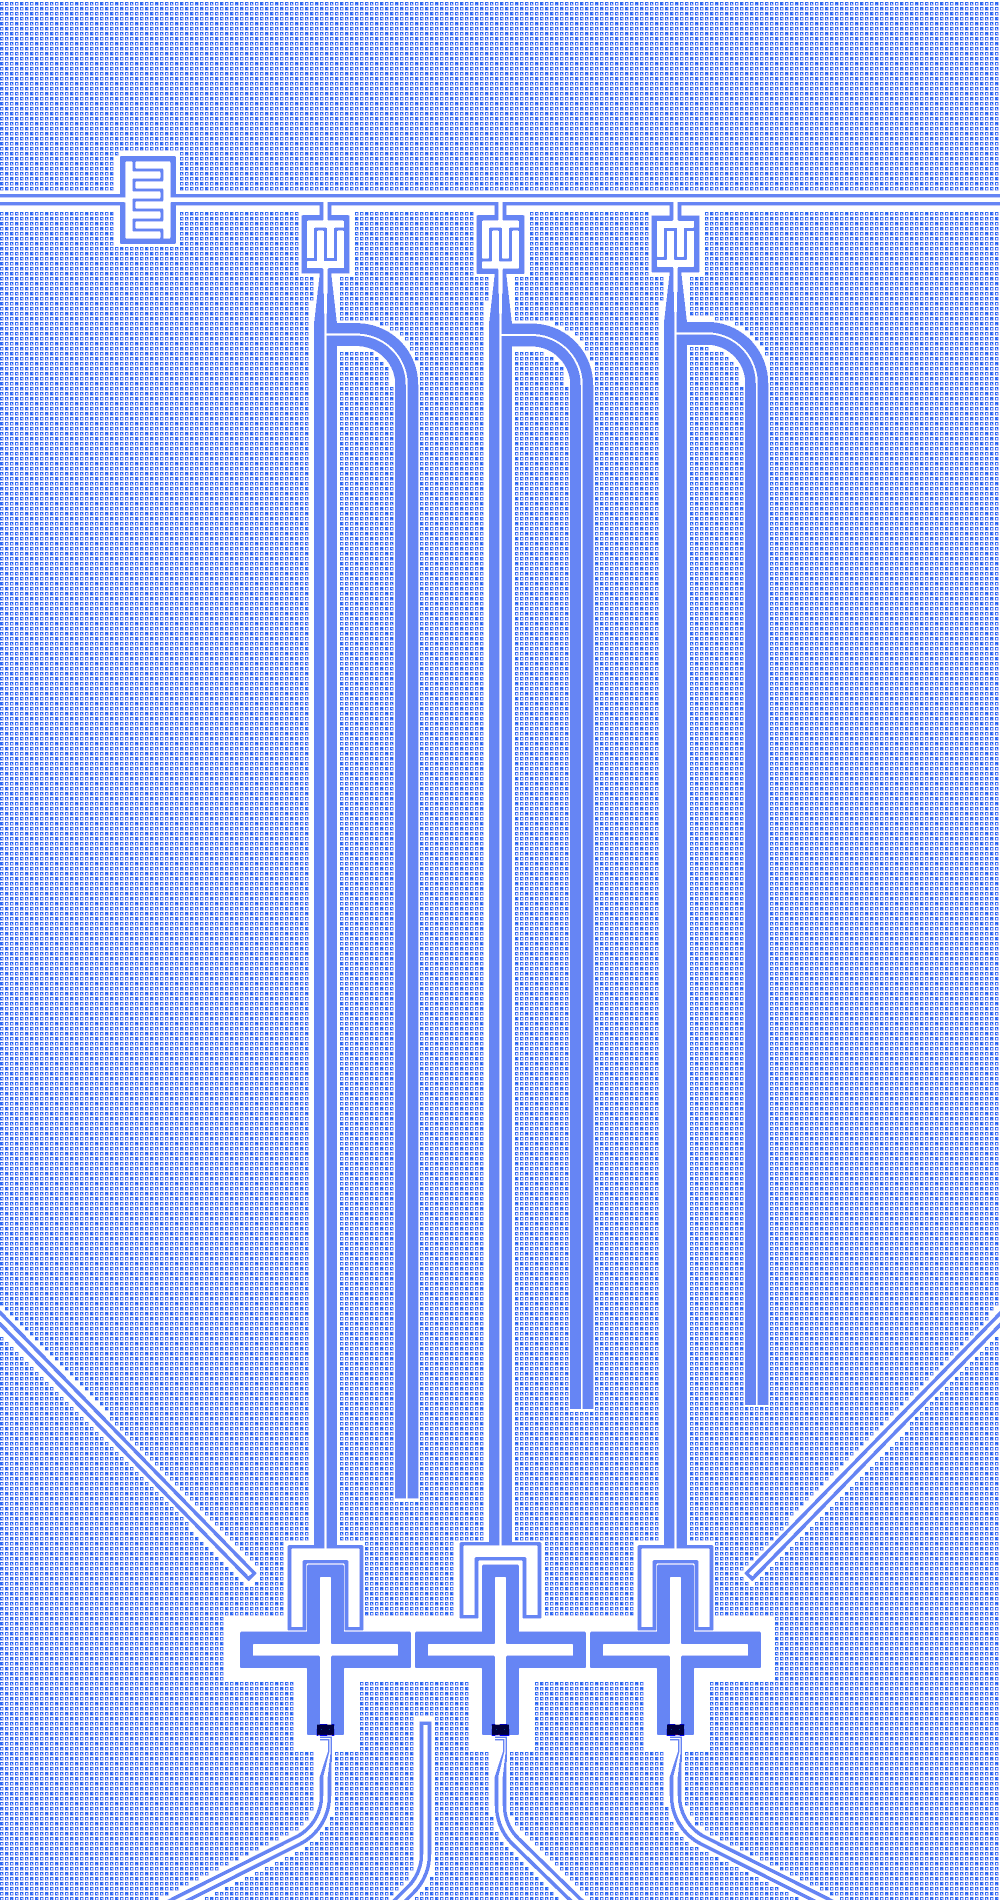

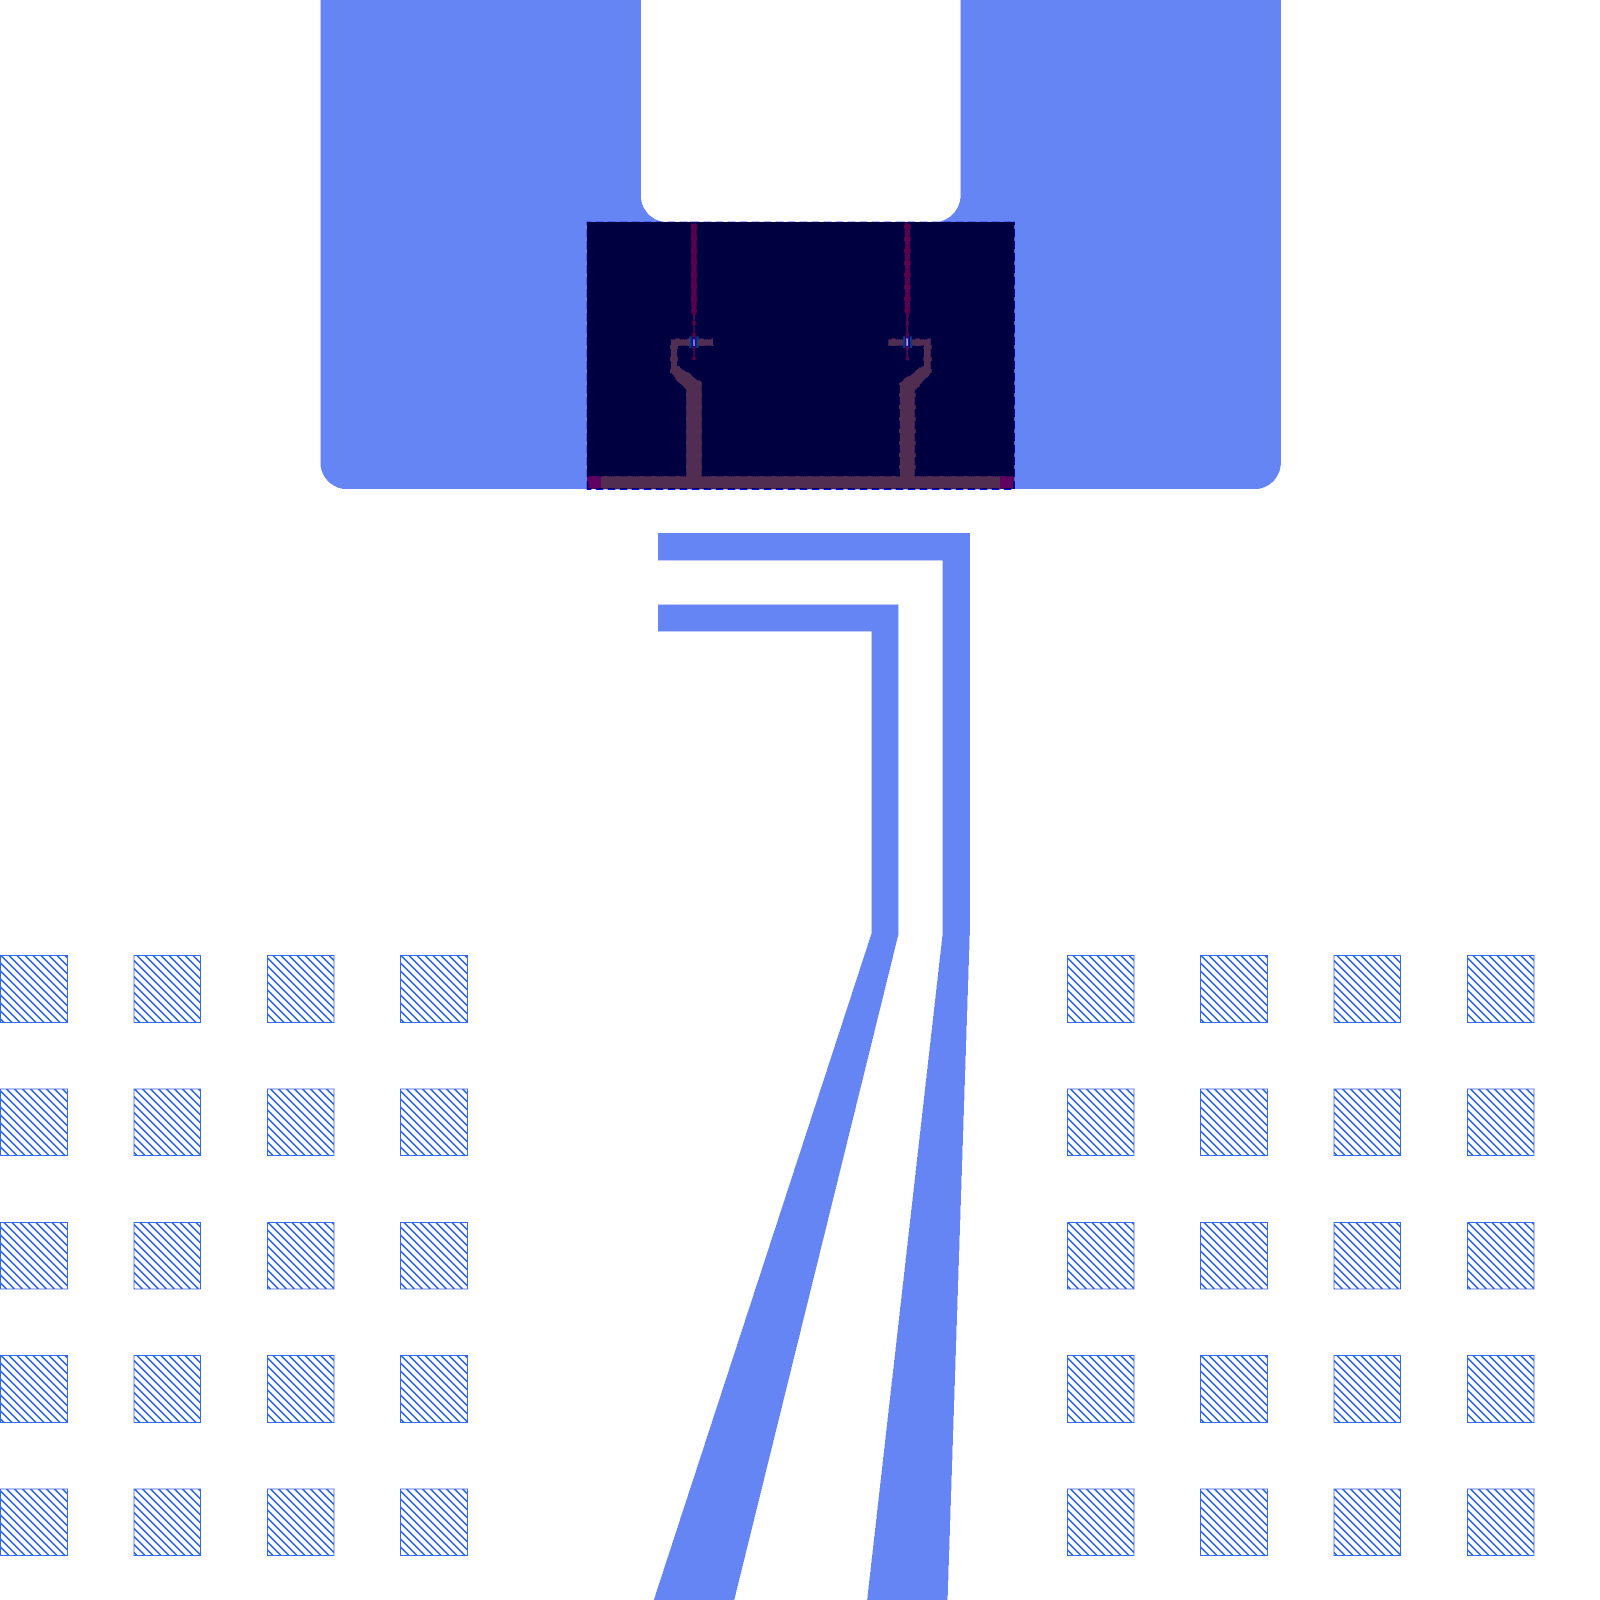

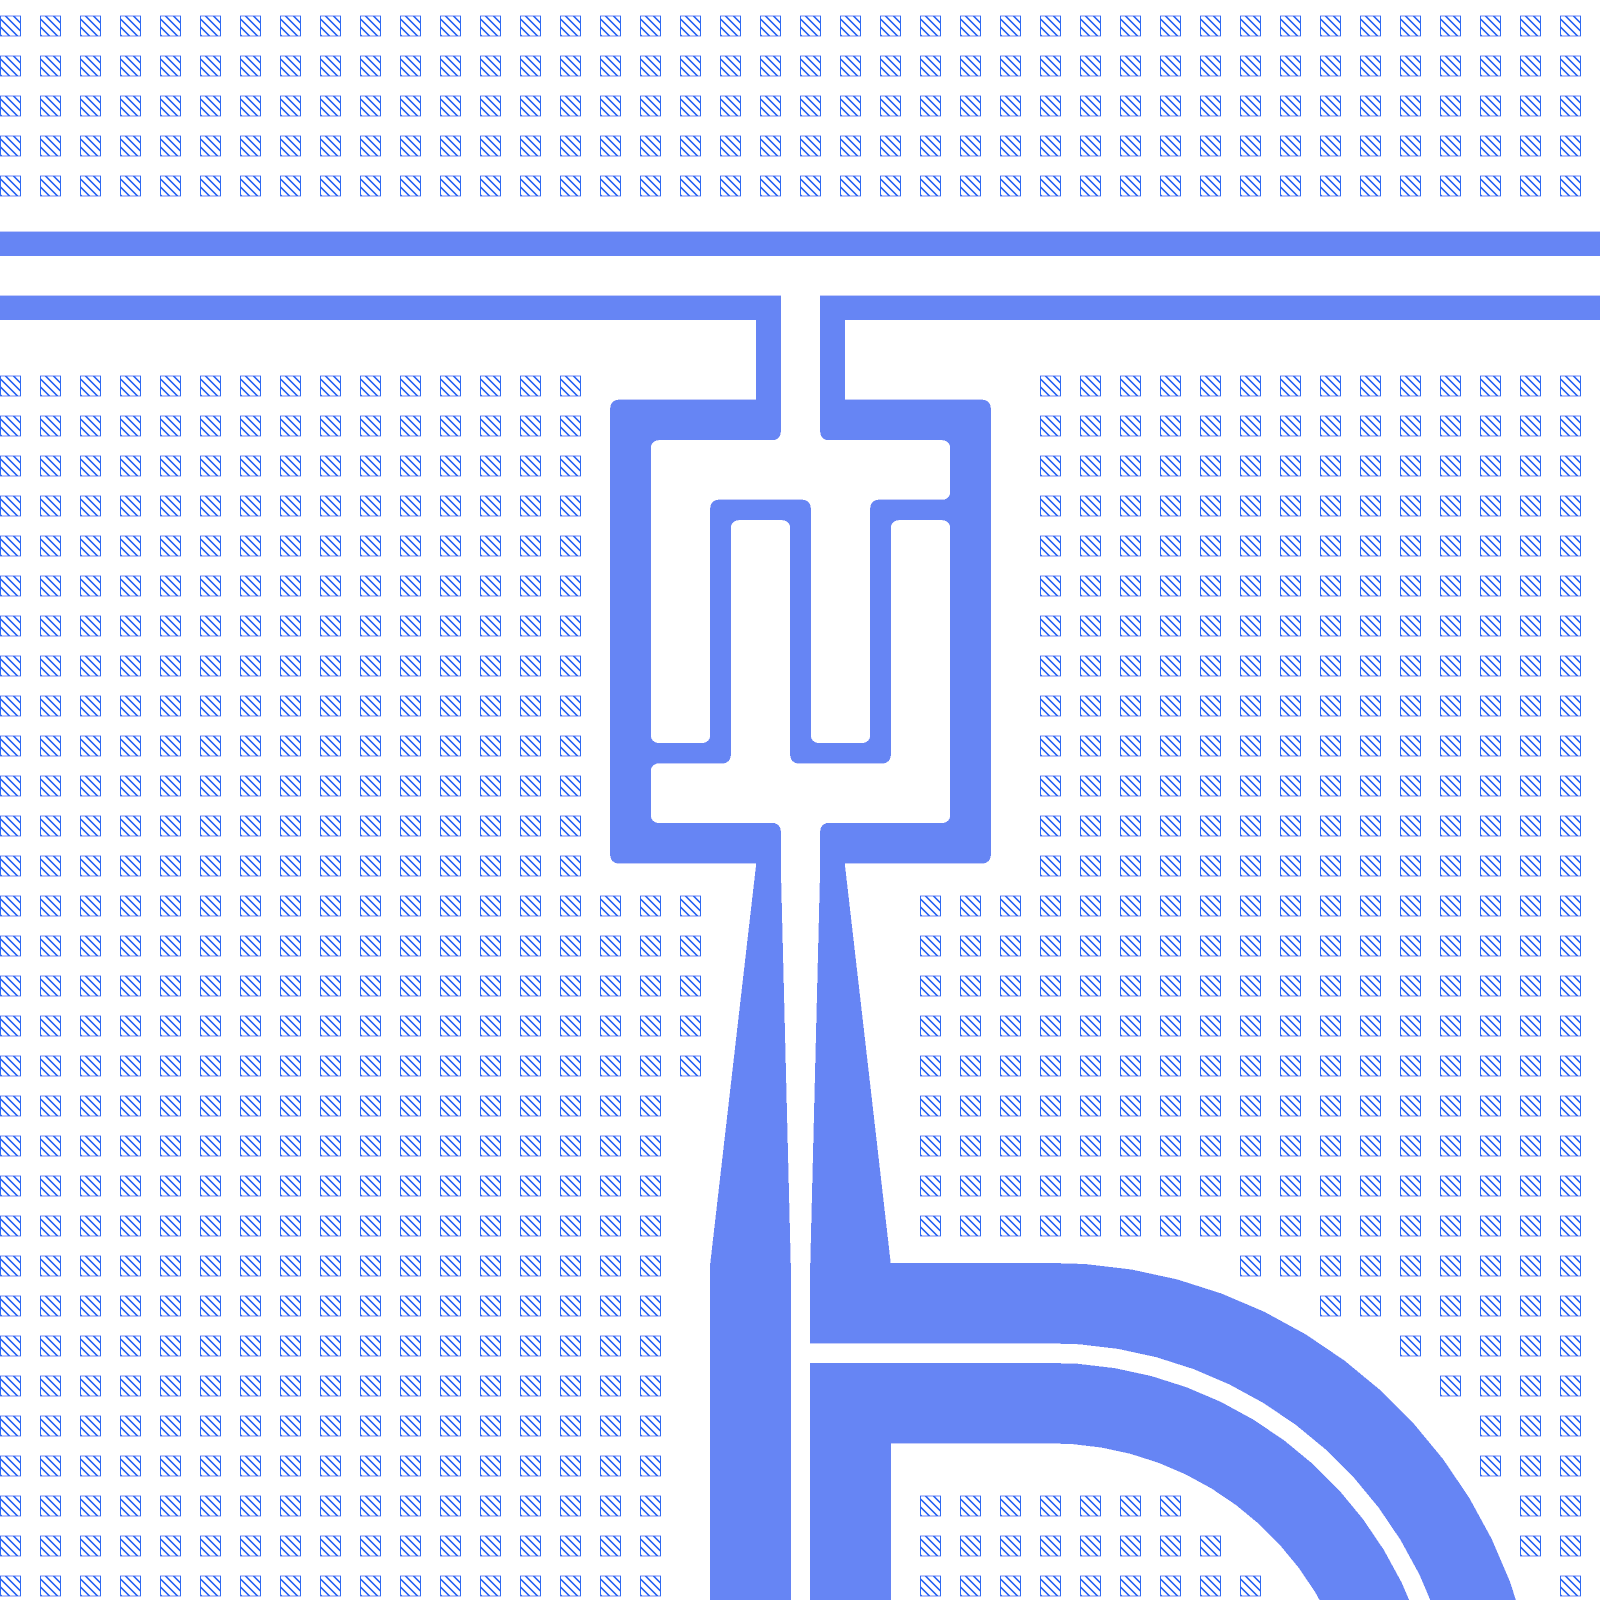

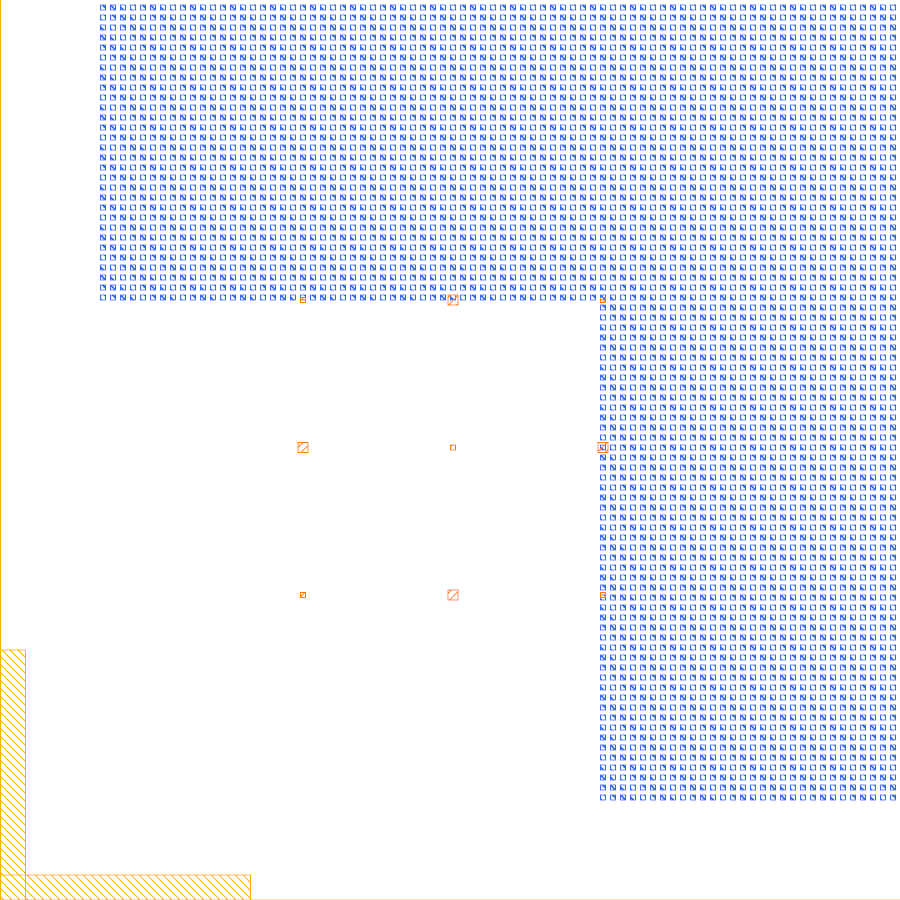

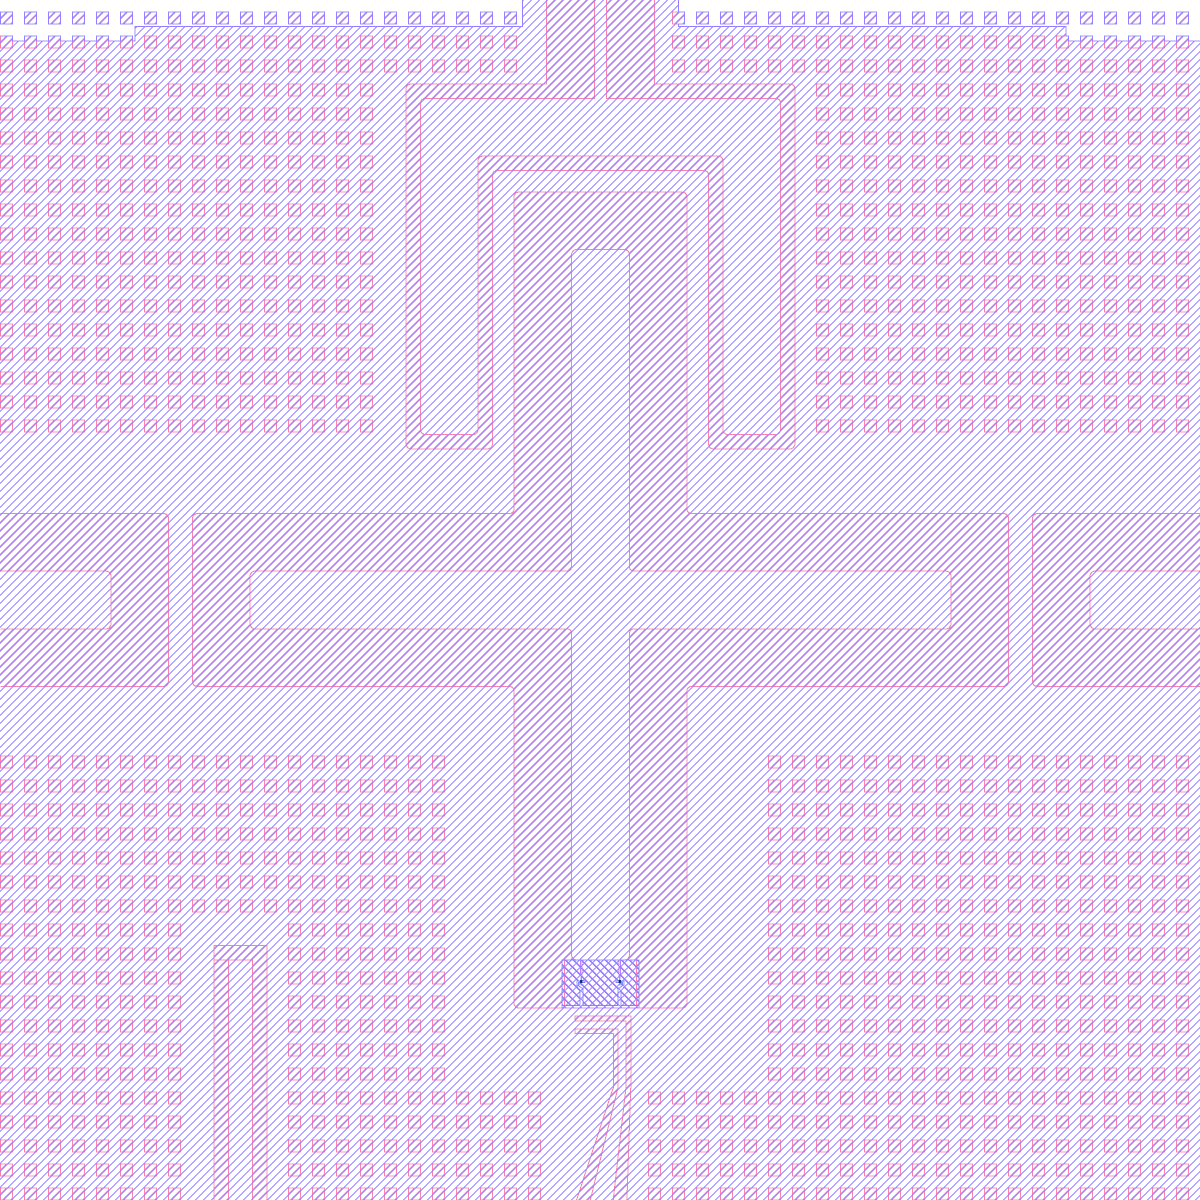

In [20]:
show_snapshot(d, OUT / "xmonsdirectcoupling.png", box=(-100, -100, 10100, 10100))   # chip only
show_snapshot(d, OUT / "xmonsdirectcoupling_qubits.png", box=(4000, 4500, 6000, 8300), size=(1000, 1900), width=360)
qx, qy = port_xy(d, "QB2.flux")
show_snapshot(d, OUT / "xmonsdirectcoupling_squid.png", box=(qx - 60, qy, qx + 60, qy + 120), width=360)
cx, cy = port_xy(d, "RC1.b")
show_snapshot(d, OUT / "xmonsdirectcoupling_coupler.png", box=(cx - 200, cy - 300, cx + 200, cy + 100), width=360)
show_snapshot(d, OUT / "xmonsdirectcoupling_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "xmonsdirectcoupling_fab.oas", OUT / "xmonsdirectcoupling_fab_qb2.png",
          box=(4750, 4750, 5250, 5250), size=(1200, 1200), width=420);   # fab view: 1/0 + 3/0 with the grid holes, junction layers

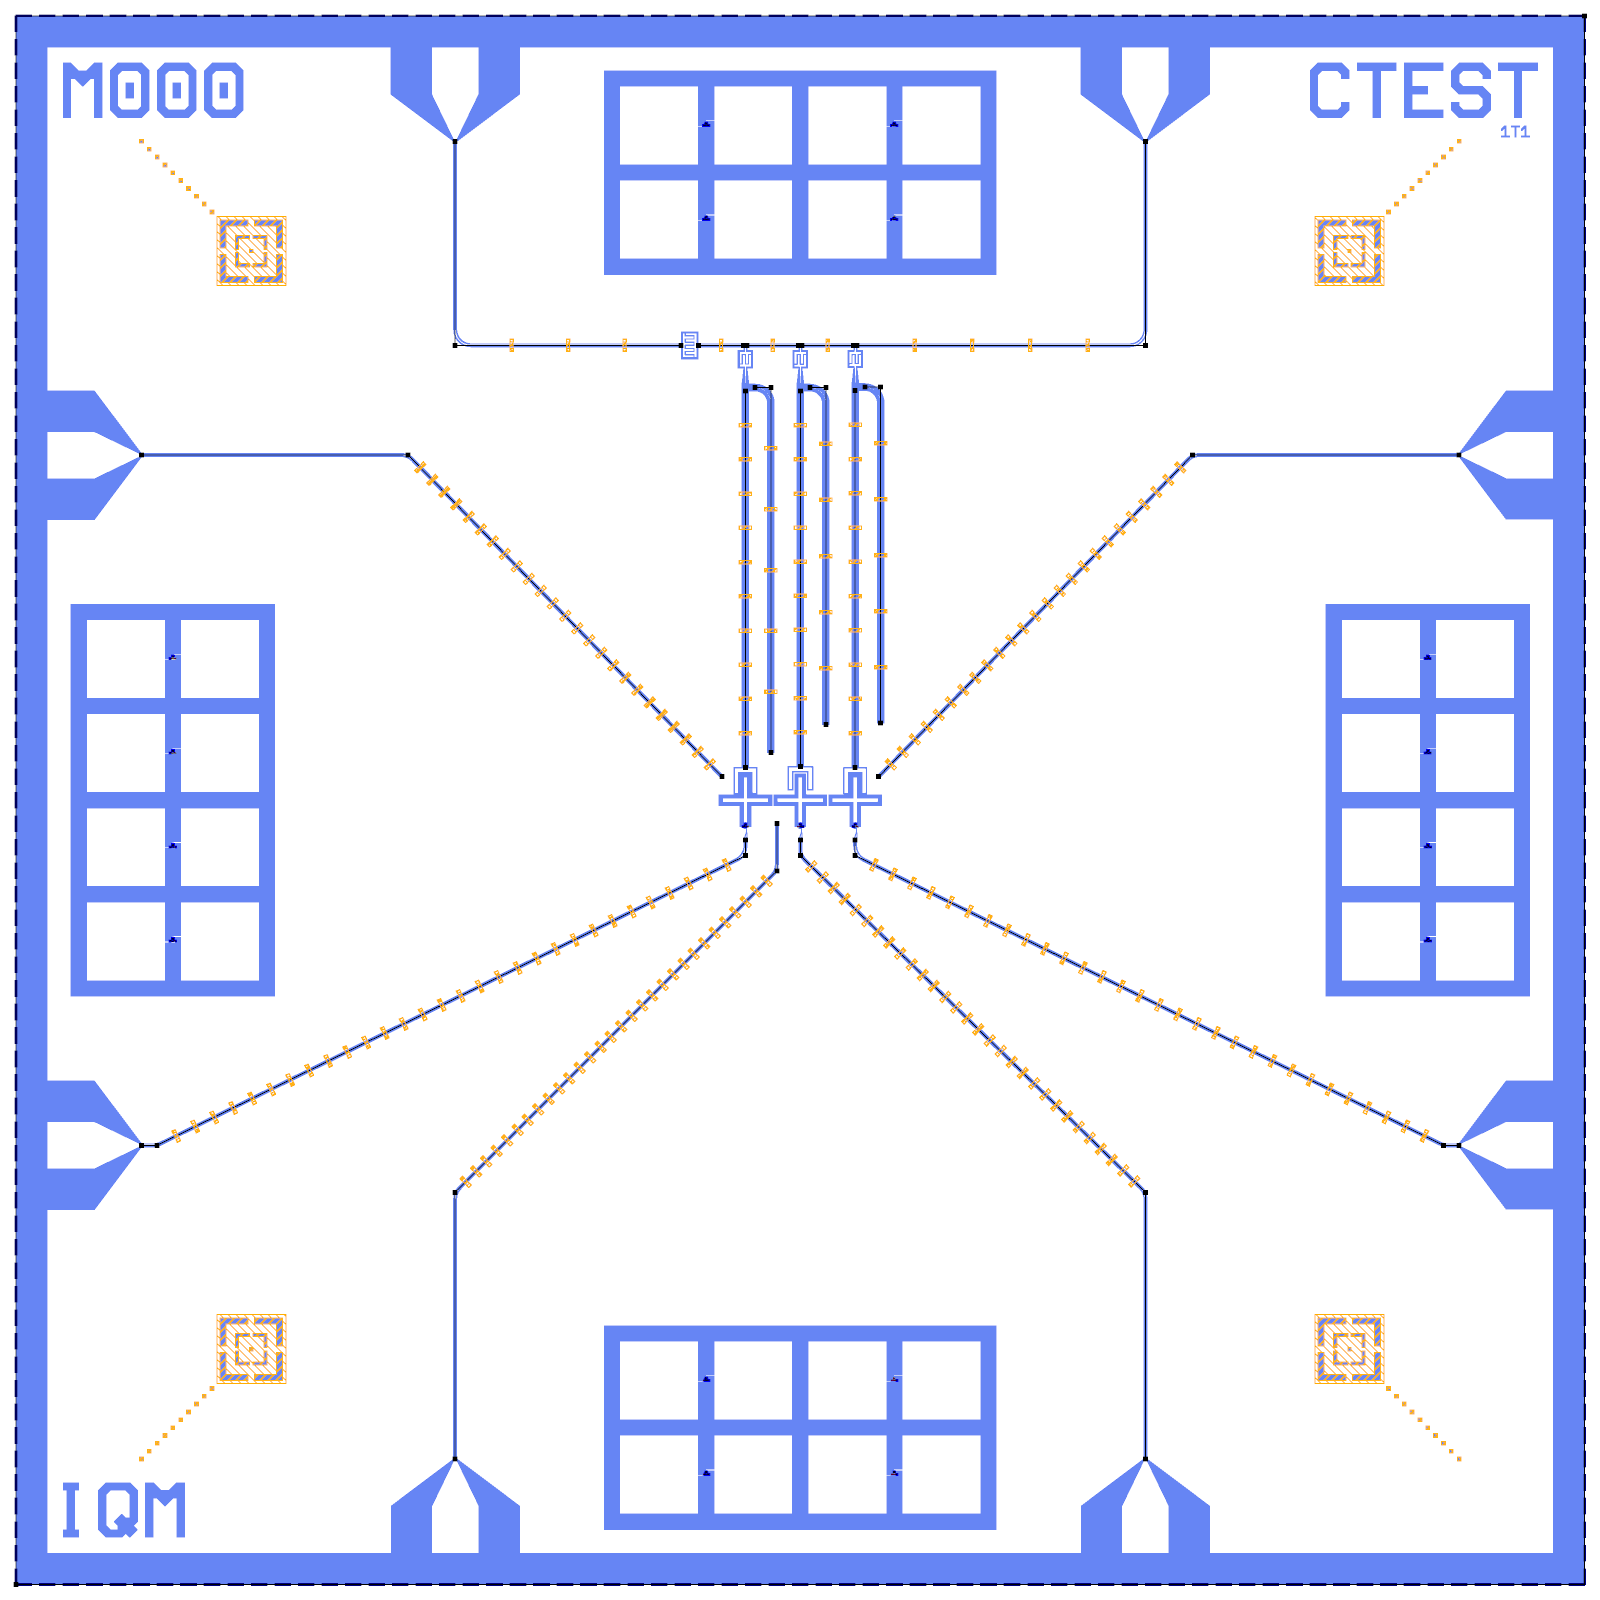

In [21]:
from kqcircuits.chips.xmons_direct_coupling import XMonsDirectCoupling
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_xmonsdirectcoupling")
top.insert(pya.DCellInstArray(XMonsDirectCoupling.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "xmonsdirectcoupling_kqc_original.oas"))
snap_file(Path("build") / "xmonsdirectcoupling_kqc_original.oas", OUT / "xmonsdirectcoupling_kqc.png", box=(-100, -100, 10100, 10100), width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; the eight SMA8 launchers and their roles; the readout chains (T → capacitor → taper → 86 Ω T) with KQC's totals 4868.6 / 4682.3 / 4686.7 µm; the probe line, charge and flux lines; the junction-test arrays; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame instead of KQC's ChipFrame; launchers 80 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire instead of silicon; Quantcore trilayer SQUIDs (f_q ≈ 6.5 GHz with the readouts, instead of ≈ 4.5 GHz) |
| **simplified** | no `n_bridges` airbridges; the direct coupling is a declared 0.3 fF until the `qubits` C-matrix is solved |
| **PDK design warnings** | as listed in step 7 |
| **FEM** | 4 Q3D jobs exported (`build/jobs/xmonsdirectcoupling_*`), not solved here |